# Lab 7 – Laplacian Filter and Mathematical & Statistical Filters

the extra experiments are in the bottom

Ali Jafar Altaweel
2240006456
7MA2

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

np.random.seed(0)   # same random noise every time the notebook runs

## 1. Laplacian filter with a manual kernel (Lab 7 A)

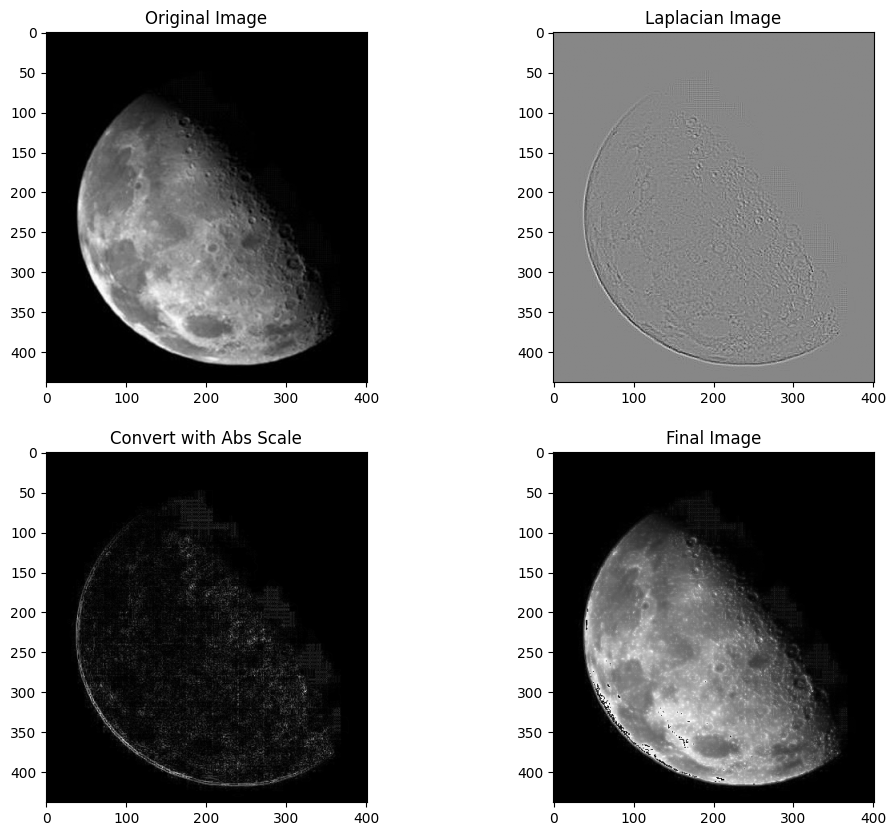

In [2]:
# ================ ( Laplacian Filter ) ===================


# 0. Image file path
# imgFile = "moon.jpg"
imgFile = "./images/moon.jpg"

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: Detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. Apply the filter using filter2D
# -1 indicates the output image will have the same depth as the source
# However, for Laplacian, use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

finalImage = img + laplacian_abs

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()

In [3]:
# quick look at the numbers
print("image :", img.shape, img.dtype)
print("Laplacian values :", laplacian_manual.min(), "to", laplacian_manual.max())
print("kernel sum =", manual_kernel.sum(), " -> flat regions give 0")

image : (438, 401) uint8
Laplacian values : -123.0 to 110.0
kernel sum = 0.0  -> flat regions give 0


## 2. Laplacian filter with cv2.Laplacian (Lab 7 A)

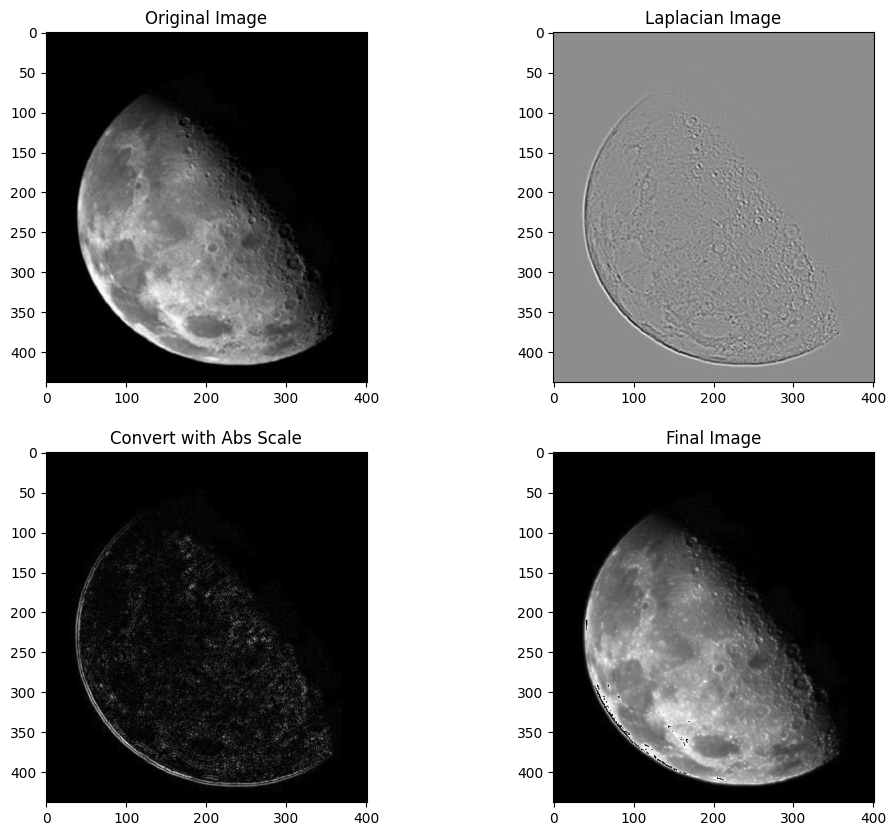

In [4]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and origianl Image
finalImage2 = img + laplacian_8bit

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()

In [5]:
# the 3x3 kernel of cv2.Laplacian (ksize=1) is the same as the manual kernel
print("same as filter2D with the manual kernel :",
      np.allclose(cv2.Laplacian(img, cv2.CV_64F), cv2.filter2D(img, cv2.CV_64F, manual_kernel)))
print("Laplacian after blur :", laplacian.min(), "to", laplacian.max())

same as filter2D with the manual kernel : True
Laplacian after blur : -66.0 to 53.0


## 3. Adding noise to an image (Lab 7 B)

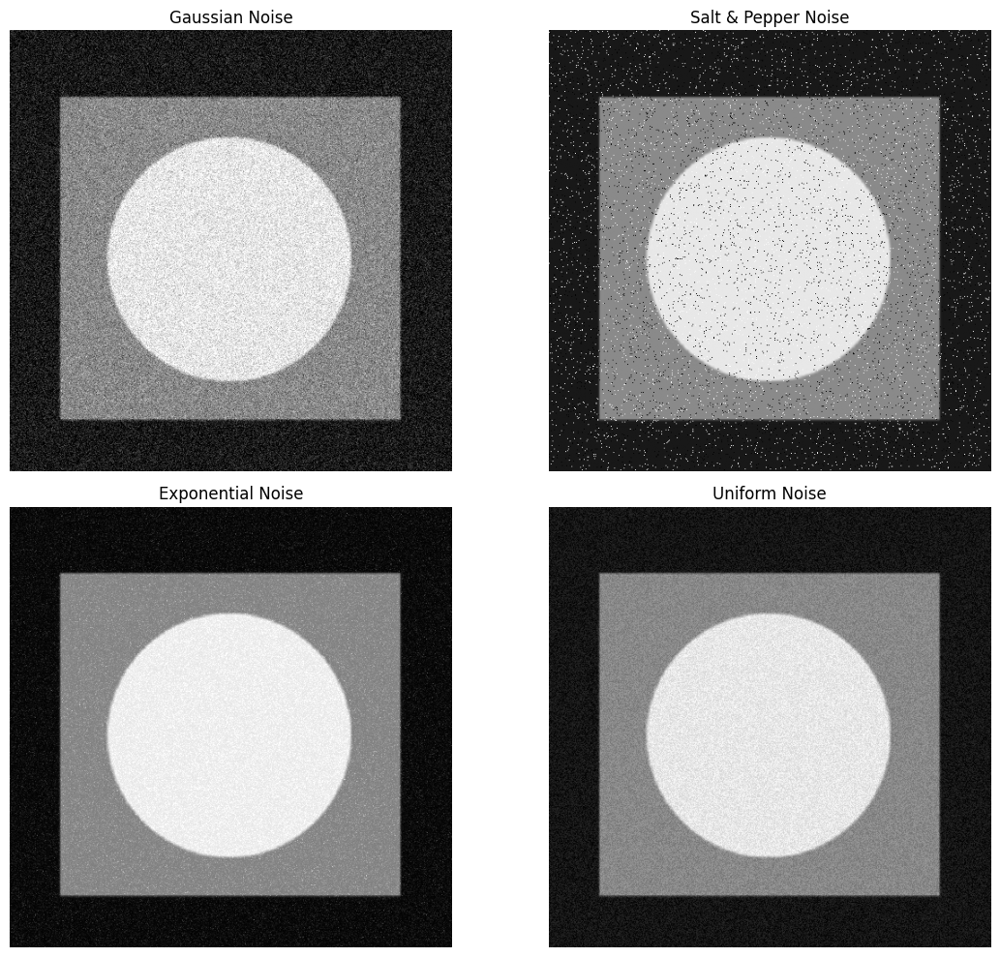

In [6]:
# ========== ( Adding nosie to an Image ) =================

# 0. Read an Image
# imgPath = 'noise.jpg'
imgPath = './images/noise.jpg'
img = cv2.imread(imgPath, 0)

# 1. Function that handle all noise algorithm (Guassian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)



# 2. Load image in grayscale
img = cv2.imread(imgPath, 0)

# 3. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 4. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')

for i in range(1, 5):
    plt.subplot(220 + i).axis('off')

plt.tight_layout()
plt.show()

clean image levels : [21 22 23 24 25] ...  gray square level = 138


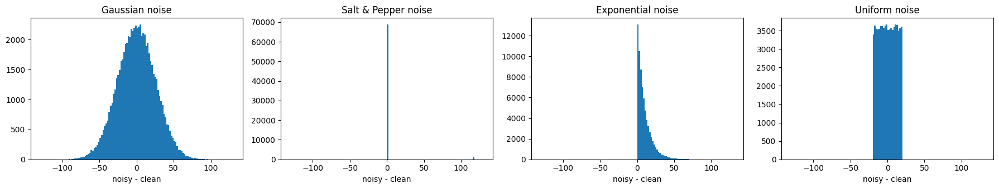

In [7]:
# histogram of the noise in the flat gray square, where the clean image is constant
noisy_set = {"Gaussian": noise_gauss, "Salt & Pepper": noise_sp,
             "Exponential": noise_expo, "Uniform": noise_uni}
gray_level = int(np.median(img[img.shape[0] // 2, 60:110]))
mask = (img == gray_level)
print("clean image levels :", np.unique(img)[:5], "...", " gray square level =", gray_level)

fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for a, (name, n) in zip(ax, noisy_set.items()):
    a.hist(n[mask].astype(int) - gray_level, bins=np.arange(-130, 131, 2))
    a.set_title(name + " noise")
    a.set_xlabel("noisy - clean")
plt.tight_layout()
plt.show()

## 4. Arithmetic mean filter

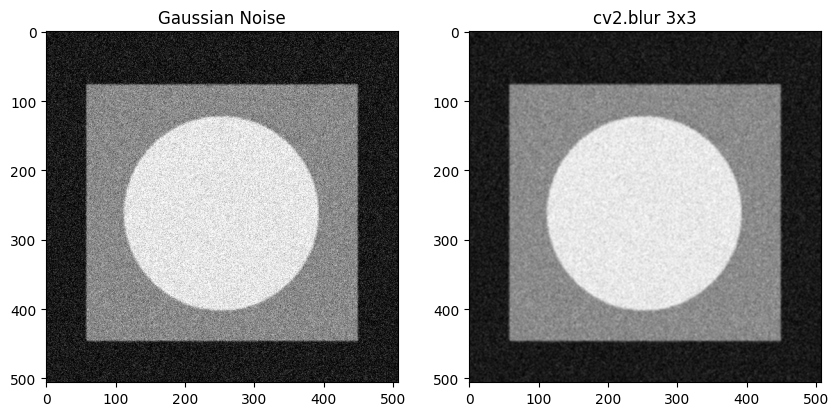

In [8]:
# --- METHOD 1: Using Built-in OpenCV function ---

# 2. Apply Arithmetic Mean Filter (using a 5x5 blur window)
# The larger the numbers in (3, 3), the smoother the image becomes.,
# you can change kernel size to (5,5), (7,7) etc.
filtered_img = cv2.blur(noise_gauss, (3, 3))

# display(filtered_img)   # shows the array as text, so plot it instead
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(122), plt.imshow(filtered_img, cmap='gray'), plt.title('cv2.blur 3x3')
plt.show()

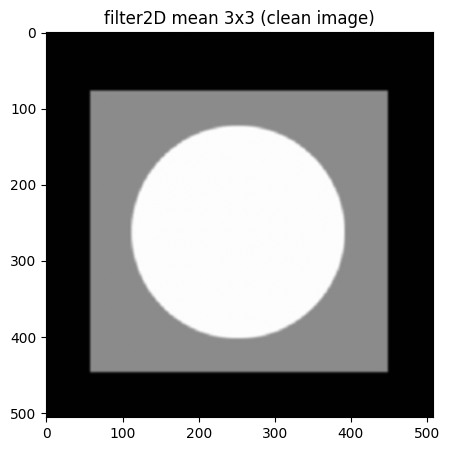

largest difference between cv2.blur and filter2D on the noisy image : 0


In [9]:
# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(img, -1, kernel)

# display(arithmetic_mean_manual)
plt.figure(figsize=(5, 5))
plt.imshow(arithmetic_mean_manual, cmap='gray'), plt.title('filter2D mean 3x3 (clean image)')
plt.show()

# the manual code filters the clean img; on the noisy image both methods agree
diff = np.abs(cv2.filter2D(noise_gauss, -1, kernel).astype(int) - filtered_img.astype(int)).max()
print("largest difference between cv2.blur and filter2D on the noisy image :", diff)

## 5. Geometric mean filter

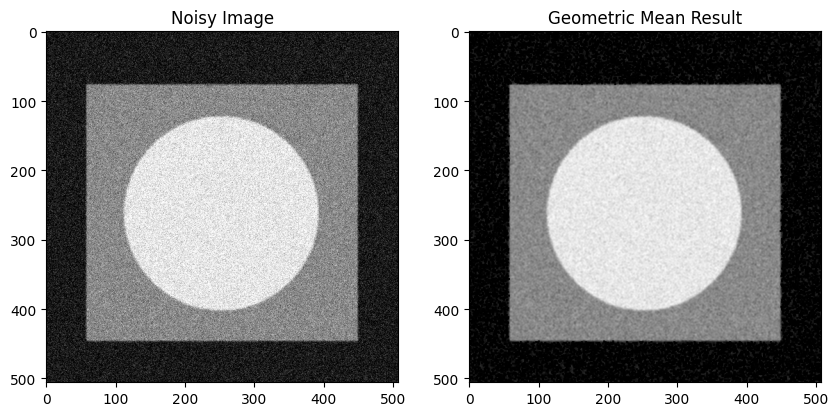

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('Geometric Mean Result')
plt.show()

## 6. Harmonic mean filter

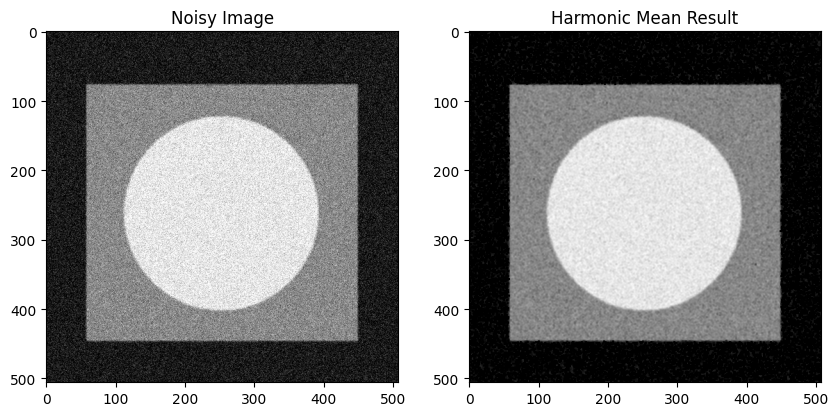

In [11]:
def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window and divide by window size
    # This is equivalent to applying a standard mean filter to the reciprocal image
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img, cmap='gray'), plt.title('Harmonic Mean Result')
plt.show()

## 7. Contra-harmonic mean filter

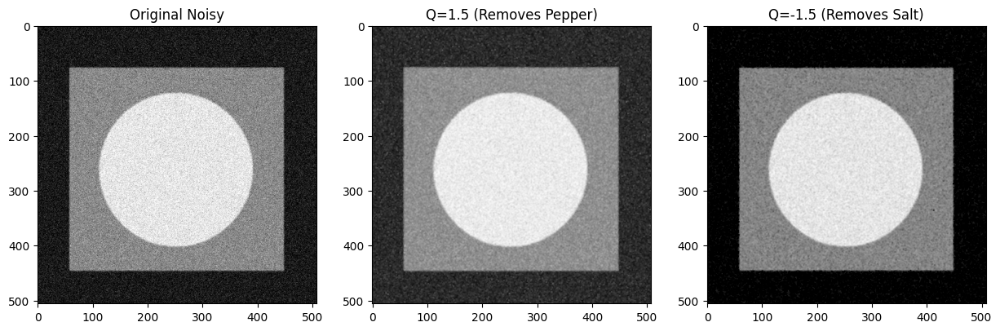

In [12]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(pepper_removed, cmap='gray'), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed, cmap='gray'), plt.title('Q=-1.5 (Removes Salt)')
plt.show()

## 8. Median filter

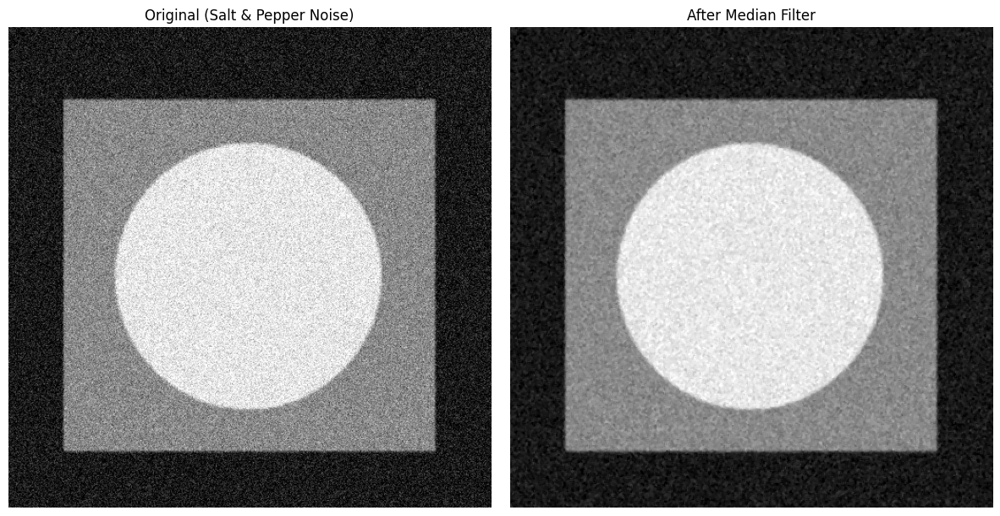

In [13]:
# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# 2. Apply Median Filter
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)

# 3. Compare Results
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Salt & Pepper Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result, cmap='gray'), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()

## 9. Max and min filters

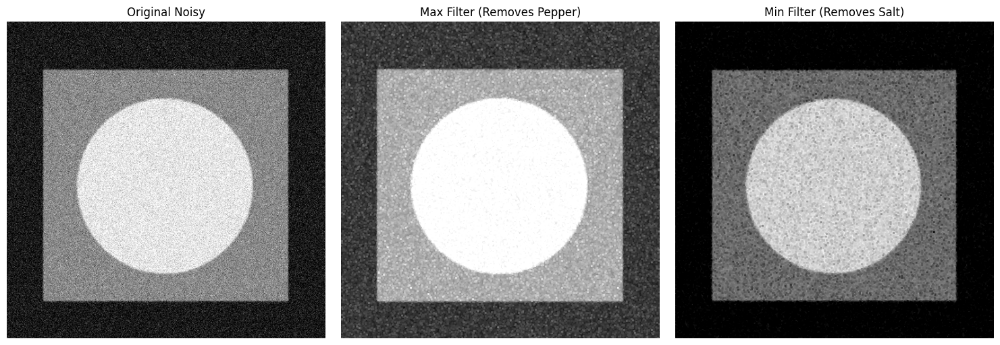

In [14]:
# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss



# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood.
max_filter = cv2.dilate(noise_img, kernel)

# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood.
min_filter = cv2.erode(noise_img, kernel)

# --- Display Results ---
plt.figure(figsize=(15, 5))

plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(max_filter, cmap='gray'), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter, cmap='gray'), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## 10. Midpoint filter

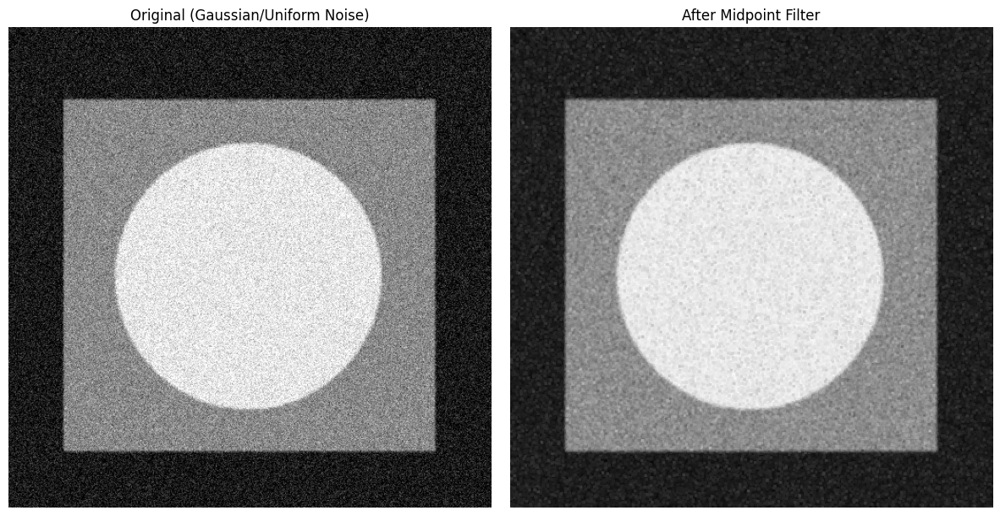

In [15]:
def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss


# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Gaussian/Uniform Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()

## 11. Extra experiments

### Experiment 1 – Laplacian sharpening without uint8 overflow

pixels that wrapped around in the manual's final image : 541


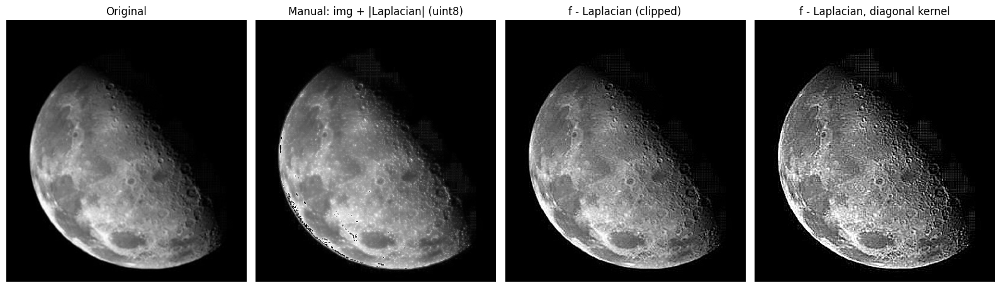

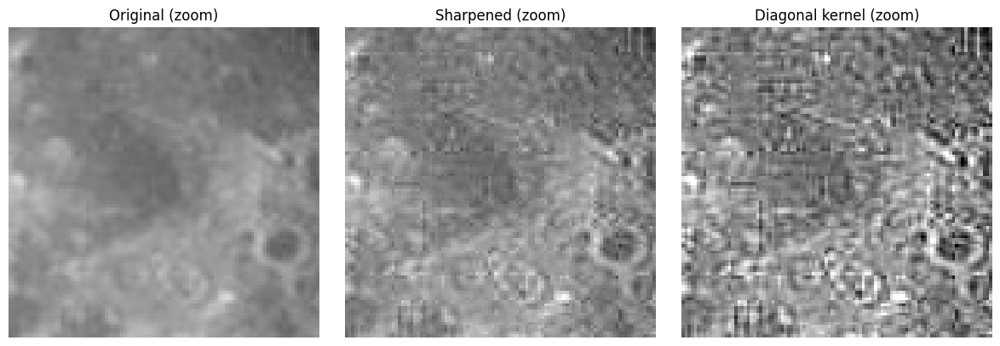

In [16]:
moon = cv2.imread("./images/moon.jpg", 0)
lap = cv2.filter2D(moon, cv2.CV_64F, manual_kernel)

# img + laplacian_abs in the manual is uint8 + uint8, so values above 255 wrap around to dark
wrapped = moon + cv2.convertScaleAbs(lap)
print("pixels that wrapped around in the manual's final image :",
      int((moon.astype(int) + cv2.convertScaleAbs(lap).astype(int) > 255).sum()))

# the center of this kernel is negative, so sharpening is f - Laplacian, done in float and clipped
sharp = np.clip(moon.astype(np.float64) - lap, 0, 255).astype(np.uint8)
# the diagonal kernel (center -8) gives a stronger sharpening
diag_kernel = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], dtype=np.float32)
sharp_diag = np.clip(moon - cv2.filter2D(moon, cv2.CV_64F, diag_kernel), 0, 255).astype(np.uint8)

plt.figure(figsize=(16, 5))
plt.subplot(141), plt.imshow(moon, cmap='gray', vmin=0, vmax=255), plt.title('Original')
plt.subplot(142), plt.imshow(wrapped, cmap='gray', vmin=0, vmax=255), plt.title('Manual: img + |Laplacian| (uint8)')
plt.subplot(143), plt.imshow(sharp, cmap='gray', vmin=0, vmax=255), plt.title('f - Laplacian (clipped)')
plt.subplot(144), plt.imshow(sharp_diag, cmap='gray', vmin=0, vmax=255), plt.title('f - Laplacian, diagonal kernel')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

# zoom on a crater region to see the difference
r0, c0 = 200, 120
plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(moon[r0:r0+100, c0:c0+100], cmap='gray', vmin=0, vmax=255), plt.title('Original (zoom)')
plt.subplot(132), plt.imshow(sharp[r0:r0+100, c0:c0+100], cmap='gray', vmin=0, vmax=255), plt.title('Sharpened (zoom)')
plt.subplot(133), plt.imshow(sharp_diag[r0:r0+100, c0:c0+100], cmap='gray', vmin=0, vmax=255), plt.title('Diagonal kernel (zoom)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

Explanation: the manual adds two uint8 images, so every sum above 255 wraps around and shows up as black specks on the bright parts of the moon. The kernel has a negative center, so the correct sharpening is the original minus the Laplacian, computed in float and clipped to 0-255.

### Experiment 2 – Every filter on every noise type

In [17]:
def psnr(clean, test):
    mse = np.mean((clean.astype(np.float64) - test.astype(np.float64)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

filters = {
    "Arithmetic": lambda x: cv2.blur(x, (3, 3)),
    "Geometric": lambda x: geometric_mean_filter(x, 3),
    "Harmonic": lambda x: harmonic_mean_filter(x, 3),
    "Contra Q=1.5": lambda x: contra_harmonic_mean(x, 3, Q=1.5),
    "Contra Q=-1.5": lambda x: contra_harmonic_mean(x, 3, Q=-1.5),
    "Median": lambda x: cv2.medianBlur(x, 3),
    "Max": lambda x: cv2.dilate(x, np.ones((3, 3), np.uint8)),
    "Min": lambda x: cv2.erode(x, np.ones((3, 3), np.uint8)),
    "Midpoint": lambda x: midpoint_filter(x, 3),
}

# PSNR in dB against the clean noise.jpg image (higher is better)
print(f"{'filter':<15}" + "".join(f"{n:>15}" for n in noisy_set))
print(f"{'(no filter)':<15}" + "".join(f"{psnr(img, n):>15.2f}" for n in noisy_set.values()))
scores = {}
for fname, f in filters.items():
    scores[fname] = [psnr(img, f(n)) for n in noisy_set.values()]
    print(f"{fname:<15}" + "".join(f"{s:>15.2f}" for s in scores[fname]))

print()
for j, name in enumerate(noisy_set):
    best = max(scores, key=lambda k: scores[k][j])
    print(f"best filter for {name:<14}: {best} ({scores[best][j]:.2f} dB)")

filter                Gaussian  Salt & Pepper    Exponential        Uniform
(no filter)              20.87          18.45          25.69          26.88
Arithmetic               30.01          27.40          28.20          35.81
Geometric                24.19          14.12          29.30          33.85
Harmonic                 23.47          13.12          29.85          31.30
Contra Q=1.5             23.33          13.99          26.19          32.35


Contra Q=-1.5            23.04          13.12          30.32          29.37
Median                   27.71          49.60          30.15          32.34
Max                      16.66          11.54          18.79          23.35
Min                      17.20          13.09          33.45          22.92
Midpoint                 27.15          15.59          25.01          37.14

best filter for Gaussian      : Arithmetic (30.01 dB)
best filter for Salt & Pepper : Median (49.60 dB)
best filter for Exponential   : Min (33.45 dB)
best filter for Uniform       : Midpoint (37.14 dB)


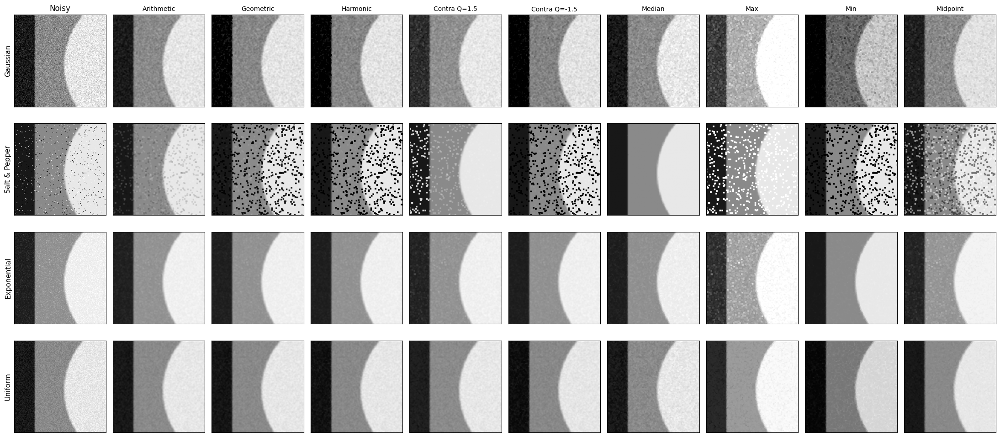

In [18]:
# visual grid: rows = noise type, columns = filter
# crop that holds the dark background, the gray square and the edge of the bright disc
crop = (slice(170, 340), slice(20, 190))
fig, ax = plt.subplots(4, len(filters) + 1, figsize=(22, 10))
for i, (nname, n) in enumerate(noisy_set.items()):
    ax[i, 0].imshow(n[crop], cmap='gray', vmin=0, vmax=255)
    ax[i, 0].set_ylabel(nname, fontsize=11)
    if i == 0: ax[i, 0].set_title("Noisy")
    for j, (fname, f) in enumerate(filters.items(), start=1):
        ax[i, j].imshow(f(n)[crop], cmap='gray', vmin=0, vmax=255)
        if i == 0: ax[i, j].set_title(fname, fontsize=10)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()

Explanation: the manual runs every filter on the Gaussian noise only, so here each filter is applied to all four noise types and scored with PSNR against the clean image. The arithmetic mean wins on Gaussian noise, the median wins by far on salt & pepper, the midpoint wins on uniform noise because that noise is bounded, and the min filter wins on exponential noise because that noise only adds brightness, so the darkest pixel of the window is the closest to the true value.

### Experiment 3 – Salt only and pepper only (contra-harmonic, max and min)

Salt only    noisy  16.75 dB | Q=1.5  10.41 dB | Q=-1.5  37.25 dB | Max   8.07 dB | Min  32.68 dB | Median  46.49 dB
Pepper only  noisy  18.30 dB | Q=1.5  39.50 dB | Q=-1.5   9.59 dB | Max  32.64 dB | Min   9.58 dB | Median  45.27 dB


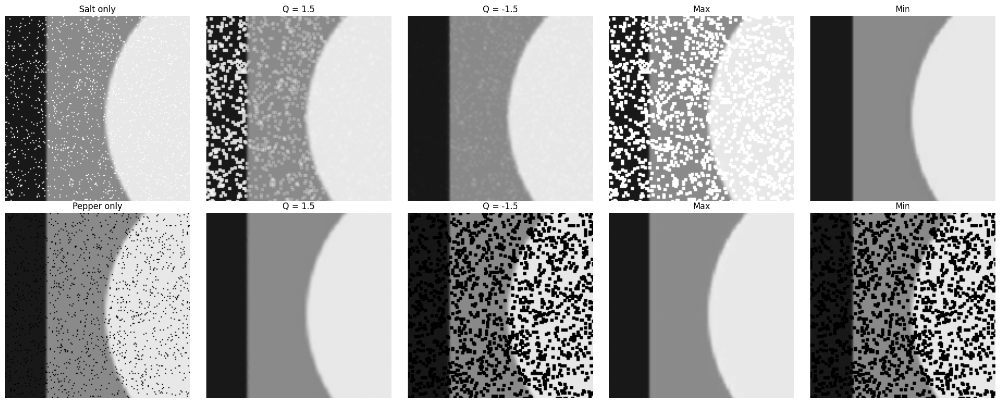

In [19]:
def add_impulse(image, value, amount=0.05):
    noisy = image.copy()
    m = np.random.rand(*image.shape) < amount
    noisy[m] = value
    return noisy

salt_only = add_impulse(img, 255)
pepper_only = add_impulse(img, 0)

tests = [("Salt only", salt_only), ("Pepper only", pepper_only)]
for name, n in tests:
    print(f"{name:<12} noisy {psnr(img, n):6.2f} dB | Q=1.5 {psnr(img, contra_harmonic_mean(n, 3, 1.5)):6.2f} dB"
          f" | Q=-1.5 {psnr(img, contra_harmonic_mean(n, 3, -1.5)):6.2f} dB"
          f" | Max {psnr(img, filters['Max'](n)):6.2f} dB | Min {psnr(img, filters['Min'](n)):6.2f} dB"
          f" | Median {psnr(img, cv2.medianBlur(n, 3)):6.2f} dB")

fig, ax = plt.subplots(2, 5, figsize=(20, 8))
for i, (name, n) in enumerate(tests):
    outs = [n, contra_harmonic_mean(n, 3, 1.5), contra_harmonic_mean(n, 3, -1.5), filters['Max'](n), filters['Min'](n)]
    titles = [name, "Q = 1.5", "Q = -1.5", "Max", "Min"]
    for j, (o, t) in enumerate(zip(outs, titles)):
        ax[i, j].imshow(o[crop], cmap='gray', vmin=0, vmax=255)
        ax[i, j].set_title(t)
        ax[i, j].axis('off')
plt.tight_layout()
plt.show()

Explanation: with salt only, Q = -1.5 and the min filter clean the image while Q = 1.5 and the max filter make it worse, and with pepper only it is the opposite. This confirms the comments in the manual: Q > 0 and max remove pepper, Q < 0 and min remove salt, and choosing the wrong sign spreads the noise.

### Experiment 4 – Effect of the kernel size

size     mean (Gaussian)   median (Gaussian)    mean (S&P)    median (S&P)
3x3                30.01               27.71         27.40           49.60
5x5                32.80               31.44         30.47           50.74
7x7                32.66               33.20         30.96           49.25
9x9                31.57               33.69         30.37           47.72


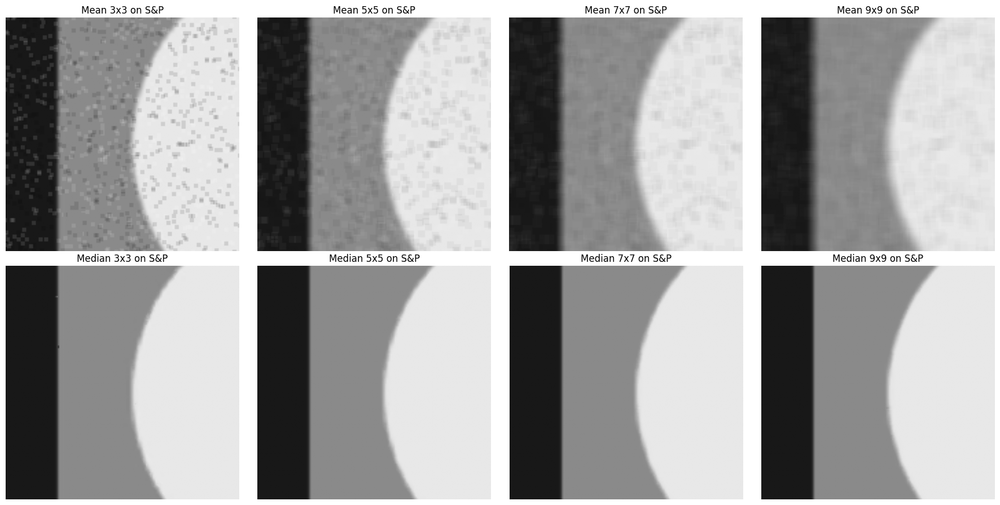

In [20]:
sizes = [3, 5, 7, 9]
print(f"{'size':<6}{'mean (Gaussian)':>18}{'median (Gaussian)':>20}{'mean (S&P)':>14}{'median (S&P)':>16}")
for k in sizes:
    print(f"{k}x{k:<4}{psnr(img, cv2.blur(noise_gauss, (k, k))):>18.2f}{psnr(img, cv2.medianBlur(noise_gauss, k)):>20.2f}"
          f"{psnr(img, cv2.blur(noise_sp, (k, k))):>14.2f}{psnr(img, cv2.medianBlur(noise_sp, k)):>16.2f}")

fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for j, k in enumerate(sizes):
    ax[0, j].imshow(cv2.blur(noise_sp, (k, k))[crop], cmap='gray', vmin=0, vmax=255)
    ax[0, j].set_title(f"Mean {k}x{k} on S&P")
    ax[1, j].imshow(cv2.medianBlur(noise_sp, k)[crop], cmap='gray', vmin=0, vmax=255)
    ax[1, j].set_title(f"Median {k}x{k} on S&P")
for a in ax.ravel(): a.axis('off')
plt.tight_layout()
plt.show()

Explanation: a bigger window removes more noise but also blurs the edges of the square and the disc. The median keeps the edges sharp for every size, while the mean turns them into a gradient and still leaves gray smudges where the salt and pepper pixels were.

### Experiment 5 – The real salt & pepper images

salt&Pepper.jpg    (224, 225)  pixels <= 20 : 5.7%   pixels >= 235 : 6.6%
salt&Pepper2.jpg   (673, 672)  pixels <= 20 : 0.0%   pixels >= 235 : 54.6%


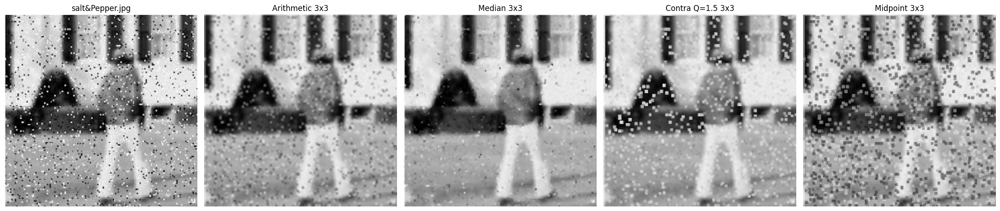

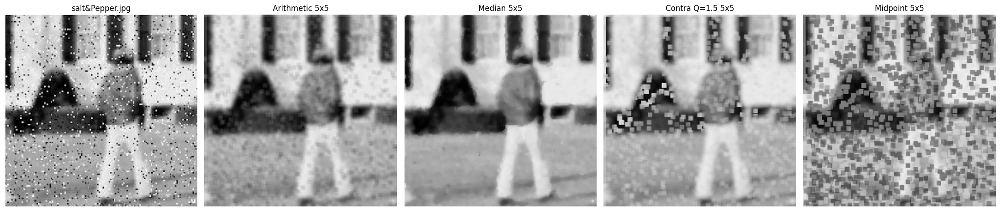

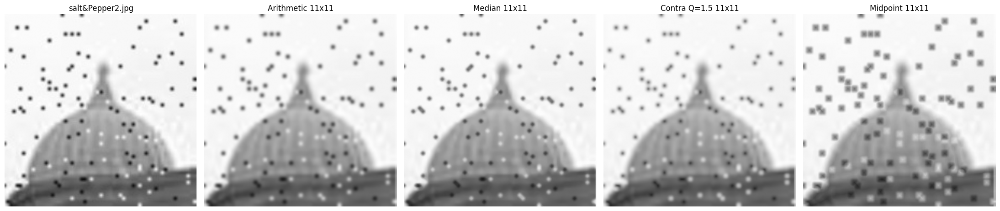

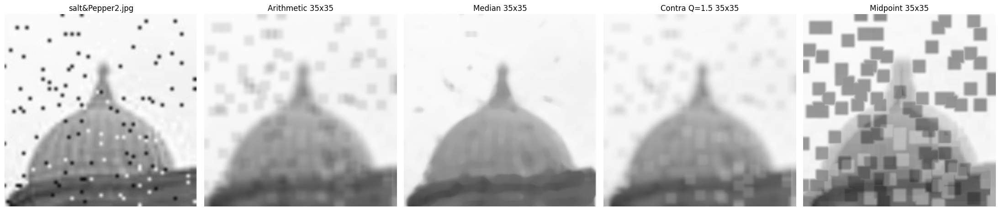

In [21]:
sp1 = cv2.imread("./images/salt&Pepper.jpg", 0)
sp2 = cv2.imread("./images/salt&Pepper2.jpg", 0)

for name, s in [("salt&Pepper.jpg", sp1), ("salt&Pepper2.jpg", sp2)]:
    print(f"{name:<18} {s.shape}  pixels <= 20 : {(s <= 20).mean() * 100:.1f}%   pixels >= 235 : {(s >= 235).mean() * 100:.1f}%")

# the dots in salt&Pepper.jpg are 1-2 pixels wide, the ones in salt&Pepper2.jpg about 16 pixels,
# and a median only removes a dot if it covers less than half of the window
cases = [
    ("salt&Pepper.jpg", sp1, 3),
    ("salt&Pepper.jpg", sp1, 5),
    ("salt&Pepper2.jpg", sp2, 11),
    ("salt&Pepper2.jpg", sp2, 35),
]
for name, s, k in cases:
    outs = [s, cv2.blur(s, (k, k)), cv2.medianBlur(s, k), contra_harmonic_mean(s, k, Q=1.5), midpoint_filter(s, k)]
    titles = [name, f"Arithmetic {k}x{k}", f"Median {k}x{k}", f"Contra Q=1.5 {k}x{k}", f"Midpoint {k}x{k}"]
    plt.figure(figsize=(22, 5))
    for j, (o, t) in enumerate(zip(outs, titles)):
        plt.subplot(1, 5, j + 1), plt.imshow(o, cmap='gray', vmin=0, vmax=255), plt.title(t), plt.axis('off')
    plt.tight_layout()
    plt.show()

Explanation: on real impulse noise the median is the only filter that removes the dots without smearing them, but the window must be more than twice as wide as a dot. On the first image the 3x3 median leaves some of the 2-pixel blobs and the 5x5 removes them, while on the second image an 11x11 window changes almost nothing and only the 35x35 median cleans the sky, at the cost of a blurrier dome. The arithmetic mean spreads the dots into gray blobs, the contra-harmonic filter with Q = 1.5 removes the black dots but enlarges the white ones, and the midpoint filter is the worst because every window that touches a dot has an extreme minimum or maximum.